In [1]:
import json
import os
import sys
from pathlib import Path


def find_project_root(start=None):
    """Walk upward from the notebook's working directory to the folder that contains src/config.py."""
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'src' / 'config.py').exists():
            return candidate
    raise FileNotFoundError(
        f'Could not find src/config.py in {start} or any parent. '
        'Place the notebook inside the project, or set PROJECT_DIR manually.')


PROJECT_DIR = find_project_root()
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

from src.config import CHECKPOINTS_DIR, FIGURES_DIR, RESULTS_DIR
from src.data import URICADSMultiTaskDataset, load_manifest
from src.engine import get_device, set_seed
from src.enhanced_cache import build_enhanced_splits
from src.metrics import best_threshold, dice_per_sample
from src.model import MultiTaskNetV2

%matplotlib inline
print('Project root:', PROJECT_DIR)

Project root: C:\StudyMaterialDoNotTouch\publications\URI-CADS dataset


In [2]:
NUM_CASES = 5
SELECTION = 'best'          # 'best' | 'worst' | 'random'
CASE_IDS = None             # e.g. ['0123', '0456'] to override SELECTION
SEED = None                 # None -> use the project default inside set_seed(); int -> used for 'random' selection
SAVE_FIGURES = False
DISPLAY_DPI = 110
SAVE_DPI = 150

SHOWCASE_DIR = os.path.join(FIGURES_DIR, 'showcase')

# Overlay colours: kidney = green (expert) / blue (model); lesion = yellow (expert) / red (model).
GT_KIDNEY, PRED_KIDNEY = '#3ddc84', '#4fc3f7'
GT_LESION, PRED_LESION = '#ffd54f', '#ff5252'

# (key, display name, checkpoint file, input source, description)
# input source: 'plain' = unenhanced image, 'enhanced' = image enhanced with the Phase 6 optimizer's parameters
PHASES = [
    ('phase4', 'Phase 4', 'phase4_multitask_local.pt', 'plain',
     'Five-head multi-task scaffold, equal loss weights, unenhanced input.'),
    ('phase5', 'Phase 5', 'phase5_anatomical_local.pt', 'plain',
     'Adds the anatomical consistency constraint (absolute-mass form).'),
    ('phase6', 'Phase 6', 'phase6_optimized_COA_local.pt', 'enhanced',
     'Loss weights and image-enhancement parameters selected by the Coati optimizer.'),
]

In [3]:
def load_model(filename, device):
    model = MultiTaskNetV2().to(device)
    state = torch.load(os.path.join(CHECKPOINTS_DIR, filename), map_location=device)
    model.load_state_dict(state)
    model.eval()
    return model


@torch.no_grad()
def predict(model, sample, device):
    image = sample['image'].unsqueeze(0).to(device)
    with torch.autocast('cuda', enabled=device.type == 'cuda'):
        out = model(image)
    kidney_logits = out['kidney_seg'].float()
    lesion_logits = out['lesion_seg'].float()
    k_gt = sample['kidney_mask'].unsqueeze(0).to(device)
    l_gt = sample['lesion_mask'].unsqueeze(0).to(device)
    local_prob = torch.sigmoid(out['local_pathology'].float())[0].cpu().numpy()
    return {
        'kidney': (torch.sigmoid(kidney_logits)[0] > 0.5).cpu().numpy(),
        'lesion': (torch.sigmoid(lesion_logits)[0] > 0.5).cpu().numpy(),
        'kidney_dice': float(dice_per_sample(kidney_logits, k_gt)[0]),
        'lesion_dice': float(dice_per_sample(lesion_logits, l_gt)[0]),
        'diagnosis_prob': float(torch.sigmoid(out['diagnosis'].float())[0].cpu()),
        'local_prob': local_prob,
    }


@torch.no_grad()
def tuned_threshold(model, dataset, device):
    """The operating point each phase would actually use: chosen on validation, never on test."""
    probs, targets = [], []
    for idx in range(len(dataset)):
        sample = dataset[idx]
        image = sample['image'].unsqueeze(0).to(device)
        with torch.autocast('cuda', enabled=device.type == 'cuda'):
            out = model(image)
        probs.append(float(torch.sigmoid(out['diagnosis'].float())[0].cpu()))
        targets.append(int(sample['global_diagnosis'].item()))
    return best_threshold(targets, probs, criterion='balanced_accuracy')


def to_display(tensor):
    """Undo the (x - 0.5) / 0.5 normalization the dataset applies."""
    return (tensor.permute(1, 2, 0).numpy() * 0.5 + 0.5).clip(0, 1)


def scan(models, datasets, device):
    """Per-case predictions and Dice for every phase, over the whole test split."""
    plain = datasets['plain']
    records = []
    for idx in range(len(plain)):
        sample = plain[idx]
        if sample['has_lesion'].item() <= 0:
            continue                      # an empty lesion panel shows nothing useful
        row = {'idx': idx, 'case_id': sample['case_id'],
               'label': int(sample['global_diagnosis'].item())}
        for key, _, _, source, _ in PHASES:
            s = sample if source == 'plain' else datasets[source][idx]
            row[key] = predict(models[key], s, device)
        row['score'] = np.mean([(row[k]['kidney_dice'] + row[k]['lesion_dice']) / 2
                                for k, *_ in PHASES])
        records.append(row)
        if (idx + 1) % 50 == 0:
            print(f'  scanned {idx + 1}/{len(plain)}', flush=True)
    return records

In [4]:
def overlay(ax, base, gt_kidney, gt_lesion, pred):
    ax.imshow(base, cmap='gray' if base.ndim == 2 else None)
    if pred is not None:
        ax.imshow(np.ma.masked_where(pred['kidney'] == 0, pred['kidney']),
                  cmap=mcolors.ListedColormap([PRED_KIDNEY]), alpha=0.22, vmin=0, vmax=1)
        ax.imshow(np.ma.masked_where(pred['lesion'] == 0, pred['lesion']),
                  cmap=mcolors.ListedColormap([PRED_LESION]), alpha=0.30, vmin=0, vmax=1)
        for mask, color in ((pred['kidney'], PRED_KIDNEY), (pred['lesion'], PRED_LESION)):
            if mask.any():
                ax.contour(mask.astype(float), levels=[0.5], colors=[color], linewidths=1.9)
        for mask, color in ((gt_kidney, GT_KIDNEY), (gt_lesion, GT_LESION)):
            if mask.any():
                ax.contour(mask, levels=[0.5], colors=[color], linewidths=1.6,
                           linestyles='dashed')
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


def diagnosis_line(pred, thresh, truth):
    """The classification output, stated as the model's actual decision at its own threshold."""
    called = 1 if pred['diagnosis_prob'] >= thresh else 0
    word = 'PATHOLOGICAL' if called else 'HEALTHY'
    mark = 'correct' if called == truth else 'INCORRECT'
    return (f'Diagnosis: {word} - {mark}\n'
            f'p = {pred["diagnosis_prob"]:.3f}  (threshold {thresh:.2f})'), mark == 'correct'


def render_case(record, datasets, thresholds, save_path=None, display_dpi=110, save_dpi=150):
    plain_sample = datasets['plain'][record['idx']]
    gt_kidney = plain_sample['kidney_mask'].numpy()
    gt_lesion = plain_sample['lesion_mask'].numpy()
    truth = record['label']

    fig, axes = plt.subplots(1, 4, figsize=(17.6, 5.6), dpi=display_dpi)
    overlay(axes[0], to_display(plain_sample['image']), gt_kidney, gt_lesion, None)
    axes[0].set_title(f'Original ultrasound - case {record["case_id"]}\n\n'
                      f'Reference diagnosis:\n'
                      f'{"PATHOLOGICAL" if truth else "HEALTHY"}',
                      fontsize=10, fontweight='bold', color='#21295C')

    for ax, (key, name, _, source, _) in zip(axes[1:], PHASES):
        sample = plain_sample if source == 'plain' else datasets[source][record['idx']]
        pred = record[key]
        overlay(ax, to_display(sample['image']), gt_kidney, gt_lesion, pred)
        lines, ok = diagnosis_line(pred, thresholds[key], truth)
        ax.set_title(f'{name} prediction\n{lines}\n'
                     f'kidney Dice {pred["kidney_dice"]:.3f}   \u00b7   '
                     f'lesion Dice {pred["lesion_dice"]:.3f}',
                     fontsize=10, fontweight='bold',
                     color='#2E7D5B' if ok else '#B5483B')

    handles = [
        mpatches.Patch(facecolor='none', edgecolor=GT_KIDNEY, linestyle='--', linewidth=1.8,
                       label='Kidney - expert annotation'),
        mpatches.Patch(facecolor=PRED_KIDNEY, edgecolor=PRED_KIDNEY, alpha=0.6,
                       label='Kidney - model prediction'),
        mpatches.Patch(facecolor='none', edgecolor=GT_LESION, linestyle='--', linewidth=1.8,
                       label='Lesion - expert annotation (bounding box)'),
        mpatches.Patch(facecolor=PRED_LESION, edgecolor=PRED_LESION, alpha=0.6,
                       label='Lesion - model prediction'),
    ]
    fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, fontsize=10,
               bbox_to_anchor=(0.5, -0.035))
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=save_dpi, bbox_inches='tight', facecolor='white')
    return fig


def select_cases(records, n, mode='best', case_ids=None, seed=None):
    """Pick which scanned cases to display."""
    if case_ids:
        wanted = [str(c) for c in case_ids]
        by_id = {str(r['case_id']): r for r in records}
        missing = [c for c in wanted if c not in by_id]
        if missing:
            print(f'Warning: case ids not found among lesion-bearing test cases: {missing}')
        return [by_id[c] for c in wanted if c in by_id]
    ordered = sorted(records, key=lambda r: r['score'], reverse=True)
    if mode == 'best':
        return ordered[:n]
    if mode == 'worst':
        return ordered[::-1][:n]
    if mode == 'random':
        rng = np.random.default_rng(seed)
        picks = rng.choice(len(records), size=min(n, len(records)), replace=False)
        return [records[i] for i in picks]
    raise ValueError(f"SELECTION must be 'best', 'worst' or 'random', got {mode!r}")


def case_caption(rank, record):
    label = 'pathological' if record['label'] == 1 else 'healthy'
    bits = '  |  '.join(
        f'{name}: p={record[key]["diagnosis_prob"]:.3f}, kidney {record[key]["kidney_dice"]:.3f}, '
        f'lesion {record[key]["lesion_dice"]:.3f}'
        for key, name, _, _, _ in PHASES)
    return f'**Figure {rank}.** Case {record["case_id"]} (reference diagnosis: {label}).  \n{bits}'


def dataset_metrics():
    """Dataset-wide test metrics for each phase, read from the saved results JSON files."""
    out = {}
    for key, _, _, _, _ in PHASES:
        name = 'phase6_final' if key == 'phase6' else key
        with open(os.path.join(RESULTS_DIR, f'{name}_results.json'), encoding='utf-8') as fh:
            out[key] = json.load(fh)['test_metrics']
    return out

In [5]:
device = get_device()
set_seed()
manifest = load_manifest()

with open(os.path.join(RESULTS_DIR, 'phase6_final_results.json'), encoding='utf-8') as fh:
    enhancement = json.load(fh)['enhancement']

print('Building test splits...', flush=True)
datasets = {'plain': URICADSMultiTaskDataset(manifest[manifest['split'] == 'test'])}
val = {'plain': URICADSMultiTaskDataset(manifest[manifest['split'] == 'val'])}

print('Precomputing Phase 6 enhanced images...', flush=True)
enh = build_enhanced_splits(manifest, enhancement, splits=('val', 'test'), quiet=True)
datasets['enhanced'], val['enhanced'] = enh['test'], enh['val']

models = {key: load_model(ckpt, device) for key, _, ckpt, _, _ in PHASES}
print(f'Device: {device} | test images: {len(datasets["plain"])} | val images: {len(val["plain"])}')

Building test splits...
Precomputing Phase 6 enhanced images...
Device: cuda | test images: 298 | val images: 298


In [6]:
print("Tuning each phase's diagnosis threshold on validation...", flush=True)
thresholds = {}
for key, name, _, source, _ in PHASES:
    thresholds[key] = tuned_threshold(models[key], val[source], device)
    print(f'  {name}: threshold {thresholds[key]:.3f}', flush=True)

Tuning each phase's diagnosis threshold on validation...
  Phase 4: threshold 0.959
  Phase 5: threshold 0.976
  Phase 6: threshold 0.985


In [7]:
print(f'Scanning {len(datasets["plain"])} test images across {len(PHASES)} phases...', flush=True)
records = scan(models, datasets, device)
print(f'{len(records)} lesion-bearing cases scanned.')

Scanning 298 test images across 3 phases...
  scanned 150/298
  scanned 200/298
203 lesion-bearing cases scanned.


In [8]:
overall = dataset_metrics()

rows = []
for key, name, _, _, desc in PHASES:
    m = overall[key]
    rows.append({
        'Phase': name,
        'Kidney Dice': round(m['kidney_dice'], 4),
        'Lesion Dice (lesion-bearing)': round(m['lesion_dice_positive_only'], 4),
        'Diagnosis AUC': round(m['diagnosis_auc'], 4),
        'Violation rate': round(m['consistency_violation_rate'], 4),
        'Diagnosis threshold': round(thresholds[key], 2),
        'Configuration': desc,
    })
metrics_df = pd.DataFrame(rows).set_index('Phase')
display(Markdown(f'**Figures computed over all {overall["phase4"]["n_samples"]} held-out test images.**'))
display(metrics_df)

**Figures computed over all 298 held-out test images.**

,Kidney Dice,Lesion Dice (lesion-bearing),Diagnosis AUC,Violation rate,Diagnosis threshold,Configuration
Phase,,,,,,
Phase 4,0.8928,0.5056,0.8995,0.2331,0.96,"Five-head multi-task scaffold, equal loss weig..."
Phase 5,0.8838,0.4868,0.8791,0.2817,0.98,Adds the anatomical consistency constraint (ab...
Phase 6,0.9081,0.4180,0.8753,0.0545,0.98,Loss weights and image-enhancement parameters ...


### Showing 5 test case(s): best 5 case(s) by mean Dice across phases

#### Case 617

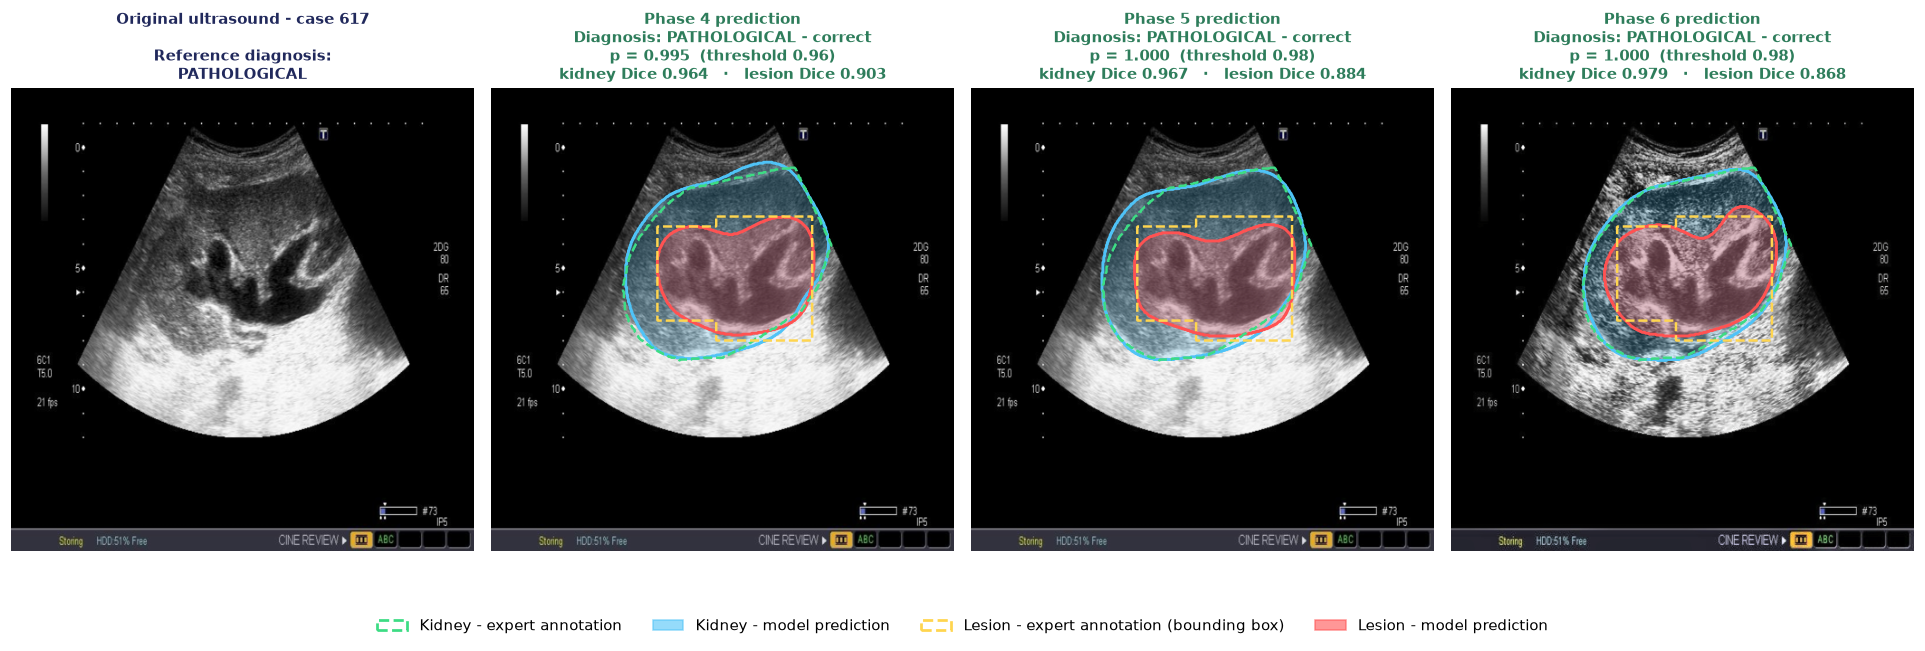

**Figure 1.** Case 617 (reference diagnosis: pathological).  
Phase 4: p=0.995, kidney 0.964, lesion 0.903  |  Phase 5: p=1.000, kidney 0.967, lesion 0.884  |  Phase 6: p=1.000, kidney 0.979, lesion 0.868

#### Case 936

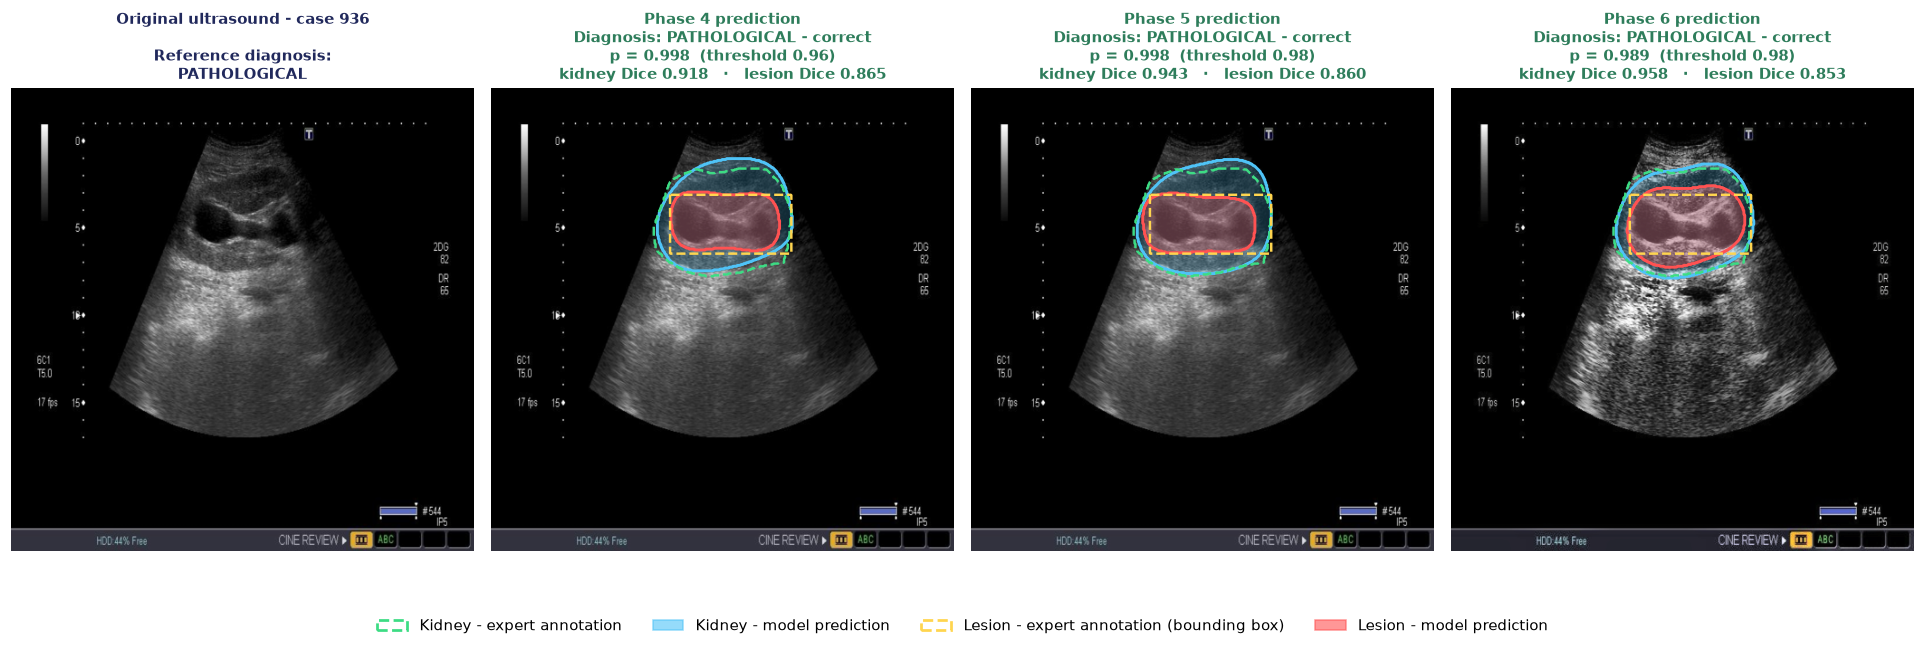

**Figure 2.** Case 936 (reference diagnosis: pathological).  
Phase 4: p=0.998, kidney 0.918, lesion 0.865  |  Phase 5: p=0.998, kidney 0.943, lesion 0.860  |  Phase 6: p=0.989, kidney 0.958, lesion 0.853

#### Case 293

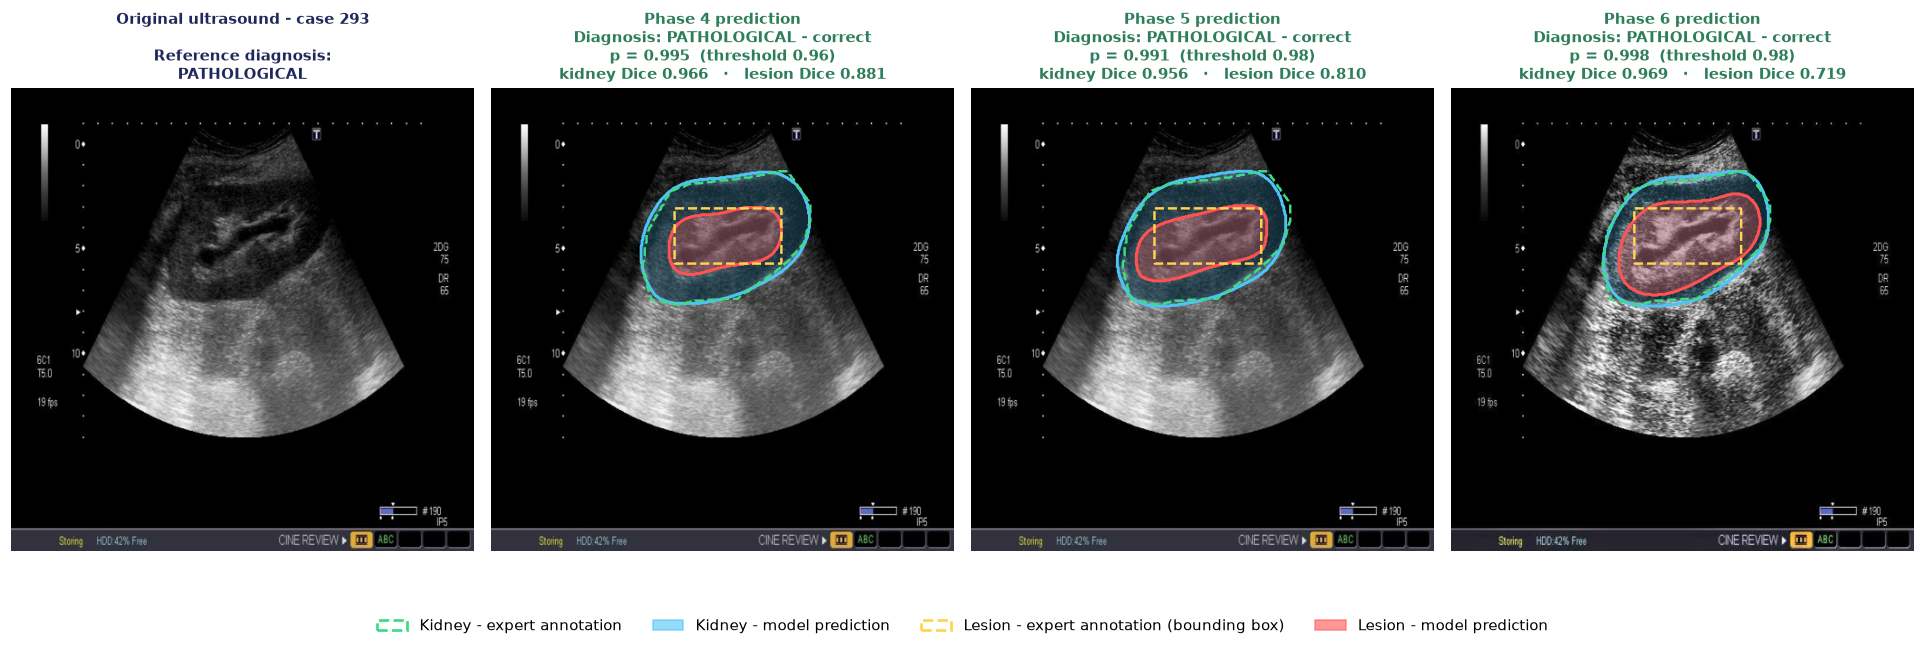

**Figure 3.** Case 293 (reference diagnosis: pathological).  
Phase 4: p=0.995, kidney 0.966, lesion 0.881  |  Phase 5: p=0.991, kidney 0.956, lesion 0.810  |  Phase 6: p=0.998, kidney 0.969, lesion 0.719

#### Case 607

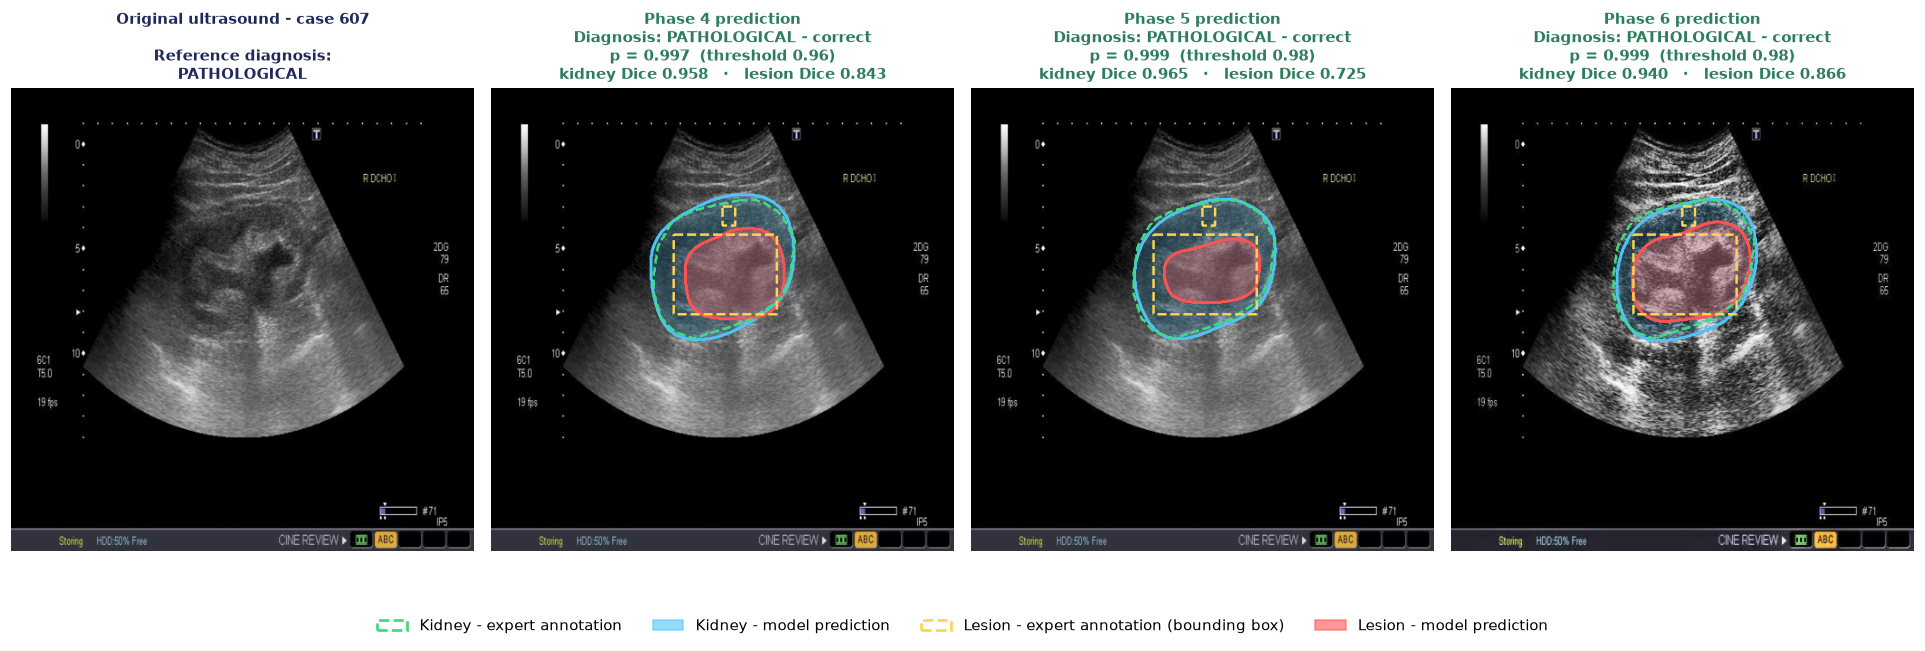

**Figure 4.** Case 607 (reference diagnosis: pathological).  
Phase 4: p=0.997, kidney 0.958, lesion 0.843  |  Phase 5: p=0.999, kidney 0.965, lesion 0.725  |  Phase 6: p=0.999, kidney 0.940, lesion 0.866

#### Case 193

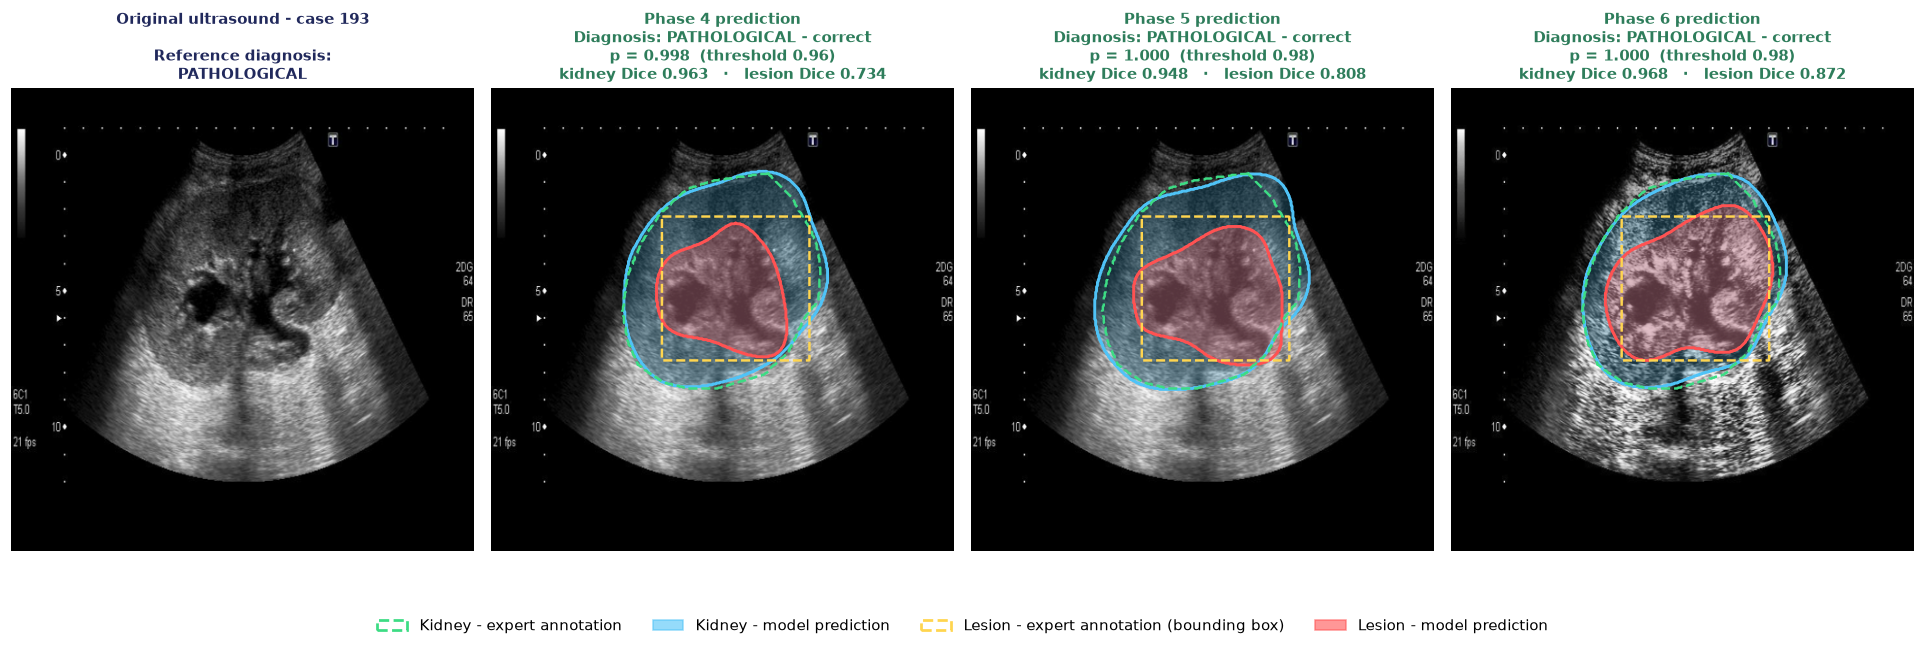

**Figure 5.** Case 193 (reference diagnosis: pathological).  
Phase 4: p=0.998, kidney 0.963, lesion 0.734  |  Phase 5: p=1.000, kidney 0.948, lesion 0.808  |  Phase 6: p=1.000, kidney 0.968, lesion 0.872

In [9]:
selected = select_cases(records, NUM_CASES, mode=SELECTION, case_ids=CASE_IDS, seed=SEED)
if SAVE_FIGURES:
    os.makedirs(SHOWCASE_DIR, exist_ok=True)

heading = ('explicit case ids' if CASE_IDS
           else f"{SELECTION} {len(selected)} case(s) by mean Dice across phases")
display(Markdown(f'### Showing {len(selected)} test case(s): {heading}'))

for rank, record in enumerate(selected, start=1):
    display(Markdown(f'#### Case {record["case_id"]}'))
    save_path = os.path.join(SHOWCASE_DIR, f'case_{record["case_id"]}.png') if SAVE_FIGURES else None
    fig = render_case(record, datasets, thresholds, save_path=save_path,
                      display_dpi=DISPLAY_DPI, save_dpi=SAVE_DPI)
    plt.show()
    plt.close(fig)
    display(Markdown(case_caption(rank, record)))
    if save_path:
        print('Saved', save_path)